In [4]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths
from matplotlib.patches import PathPatch

In [31]:
df = pd.read_csv('ScoreIntzones_merged.csv')
df = df.drop('Cups Hab', 1)

/var/folders/b7/k9l5l5ss13d27wd57vb8fq4w0000gn/T/ipykernel_82339/3330542407.py:2: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only.
  df = df.drop('Cups Hab', 1)


In [32]:
data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
print(newdf)

   Experimental Condition  Left preference control
0                Cups LTM         0.029126       y
1                Cups LTM        -0.040816       n
2                Cups LTM         0.236364       n
3                Cups LTM         0.028058       y
4                Cups LTM         0.128205       n
..                    ...              ...     ...
95                    LTM         0.000000       n
96                    LTM         0.821699       n
97                    LTM         0.840000       n
98                    LTM         0.166667       y
99                    LTM         0.228261       n

[100 rows x 3 columns]


In [33]:
df_h = pd.read_csv('ScoreHalves_merged.csv')
df_h = df_h.drop('Cups Hab', 1)
print(df_h.loc[df_h['Control']=='y',:])

    Group  Cups LTM       LTM Control
0       1  0.016000  0.100000       y
3       4  0.070000 -0.016000       y
5       6 -0.080000 -0.085333       y
10     11 -0.022667 -0.158000       y
15     16  0.092000  0.018000       y
16     17  0.120667  0.127333       y
17     18 -0.030667  0.108000       y
19     20  0.103333  0.045333       y
23     24  0.012667 -0.069333       y
24     25 -0.088000  0.076000       y
27     28  0.084667 -0.079333       y
28     29  0.138000  0.032667       y
29     30 -0.174000 -0.180000       y
31     32  0.182047  0.060933       y
32     33  0.083333  0.041000       y
33     34  0.024400  0.057667       y
35     36  0.071067 -0.104000       y
36     37 -0.134667 -0.081227       y
37     38 -0.071067  0.120000       y
38     39  0.061204  0.340000       y
39     40 -0.031333  0.041333       y
40     41 -0.039267 -0.122733       y
41     42  0.009333  0.183867       y


/var/folders/b7/k9l5l5ss13d27wd57vb8fq4w0000gn/T/ipykernel_82339/2528585791.py:2: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only.
  df_h = df_h.drop('Cups Hab', 1)


In [34]:
data = []

for el in df_h.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df_h[el]):
        data.append([el,val,df_h.iloc[i].get('Control')])
        
newdf_h = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
# print(newdf)
newdf_h = newdf_h.replace({'Cups LTM': "Cups LTM halves", "LTM": "LTM halves"})

newdf = pd.concat([newdf_h,newdf])
newdf

,Experimental Condition,Left preference,control
0,Cups LTM halves,0.016000,y
1,Cups LTM halves,-0.020667,n
2,Cups LTM halves,0.225333,n
3,Cups LTM halves,0.070000,y
4,Cups LTM halves,0.125333,n
...,...,...,...
95,LTM,0.000000,n
96,LTM,0.821699,n
97,LTM,0.840000,n
98,LTM,0.166667,y


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


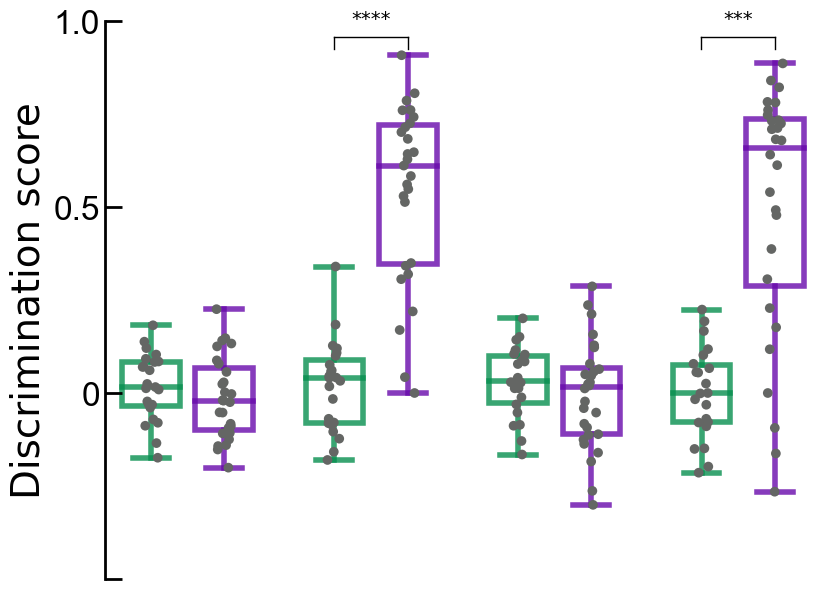

In [35]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}


text_boxplot = ['','***','****']

colors = ["#646664","#646664"]
colors_boxplot = ['#078f4f', "#680aab"]

ax = sns.stripplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    size=7,
    palette=colors,
    jitter=0.09,
    dodge=True
)


locs = ["upper left"]
boxplot = sns.boxplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    palette=colors_boxplot,
    fliersize=0,
    linewidth=4,
    **PROPS
)

#plt.axhline(linewidth=2, color='grey',ls='--')
#plt.axvline(linewidth=2, x=1.5, color='#f29a94',ls='--')


data_ratio = 0.4016222222466667

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_linewidth(2)


#CHANGE BOXPLOT STYLE

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches

for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[i%2]
    patch.set_edgecolor(col)
    patch.set_facecolor('None')
    
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        
        
#END CHANGE BOXPLOT STYLE

#ax.text(-0.16,1.15,'Arena half', fontsize = 30)
#ax.text(1.55,1.15,'Interaction zone', fontsize = 30)

plt.legend([],[], frameon=False)

ax.set_xticklabels(['Cups','CS-','Cups','CS-'], fontsize = 26)
ax.set_xticks([])
ax.set_xlabel("",fontsize=20)
ax.set_ylabel('Discrimination score', fontsize = 28)

ax.set_ylim([-0.5,1])
ax.set_yticks([-0.5,0,0.5,1], fontname='Arial')
ax.set_yticklabels(['','0','0.5','1.0'],fontname='Arial')

ax.set_xlim([-0.45,3.5])

significance(ax,1,data_ratio,newdf.loc[newdf['Experimental Condition']=='LTM']['Left preference'].max(),text=text_boxplot[2])
significance(ax,3,data_ratio,newdf.loc[newdf['Experimental Condition']=='LTM']['Left preference'].max(),text=text_boxplot[1])

ax.tick_params(axis='y', which='major', direction='in',length=12, labelsize=24, width=2)


fig = ax.get_figure()

adjust_box_widths(fig, 0.8)
fig.set_size_inches(8.5,6)

plt.tight_layout()
fig.tight_layout()
fig.savefig("Fig_Scores_Halves_Intzones_v2.jpg",dpi=500,bbox_inches='tight')
plt.savefig('Fig_Scores_Halves_Intzones_v2.eps', format='eps')

